In [8]:
!pip install yfinance -q

In [9]:
#Step 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

# Set styling for plots
sns.set_theme(style="darkgrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
#Install and Import Libraries
ticker_symbol = "AAPL"  # You can change this to 'MSFT', 'GOOGL', etc.
stock_data = yf.download(ticker_symbol, start="2020-01-01", end="2026-01-01")

print(f"Dataset Shape: {stock_data.shape}")
display(stock_data.head())

/tmp/ipykernel_8565/3549054675.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(ticker_symbol, start="2020-01-01", end="2026-01-01")
[*********************100%***********************]  1 of 1 completed

Dataset Shape: (1508, 5)


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271530,72.331686,71.029908,71.282560,135480400
2020-01-03,71.568901,72.326866,71.345122,71.501527,146322800
2020-01-06,72.139191,72.177691,70.442792,70.693043,118387200
2020-01-07,71.799911,72.403874,71.580942,72.148812,108872000
2020-01-08,72.954918,73.255698,71.503953,71.503953,132079200


In [11]:
#Data Cleaning & Preprocessing Check
# Check for missing values
print("Missing values per column:\n", stock_data.isnull().sum())

stock_data = stock_data.dropna()

# Check dataset basic statistics
display(stock_data.describe())

Missing values per column:
 Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
count,1508.000000,1508.000000,1508.000000,1508.000000,1.508000e+03
mean,164.493894,166.173689,162.648110,164.333157,8.453734e+07
std,49.583692,49.874216,49.243945,49.540650,5.136424e+07
min,54.117031,55.113170,51.280573,55.011868,1.791060e+07
25%,131.065277,132.521785,129.705053,131.470018,5.075645e+07
50%,162.903618,165.029876,161.630812,163.161525,7.040210e+07
75%,197.028122,198.948822,194.179757,196.391090,1.005718e+08
max,285.413116,287.836529,282.530963,285.423116,4.265100e+08


In [12]:
#Exploratory Data Analysis (EDA) & Feature Engineering
#Calculate Moving Averages & Feature Engineering
# Calculate 50-day and 200-day Simple Moving Averages (SMA)
stock_data['SMA_50'] = stock_data['Close'].rolling(window=50).mean()
stock_data['SMA_200'] = stock_data['Close'].rolling(window=200).mean()

# Create a target variable: Predict the 'Close' price of the next day
stock_data['Target'] = stock_data['Close'].shift(-1)

# Drop rows with NaN values created by rolling windows and shifting
stock_data_eda = stock_data.dropna()

print("Features engineered successfully! New shape:", stock_data_eda.shape)
display(stock_data_eda.head())

Features engineered successfully! New shape: (1308, 8)


Price,Close,High,Low,Open,Volume,SMA_50,SMA_200,Target
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,,,
Date,,,,,,,,
2020-10-15,116.984642,117.459518,114.503651,115.056060,112559200,113.310527,85.649375,115.346771
2020-10-16,115.346771,117.798696,115.143253,117.537025,115393800,113.413691,85.864751,112.400604
2020-10-19,112.400604,116.703571,112.090480,116.257769,120639300,113.508037,86.068910,113.883400
2020-10-20,113.883400,115.308034,112.061416,112.613824,124423700,113.600735,86.277631,113.263153
2020-10-21,113.263153,115.046363,112.856110,113.069321,89946000,113.746009,86.484947,112.177689


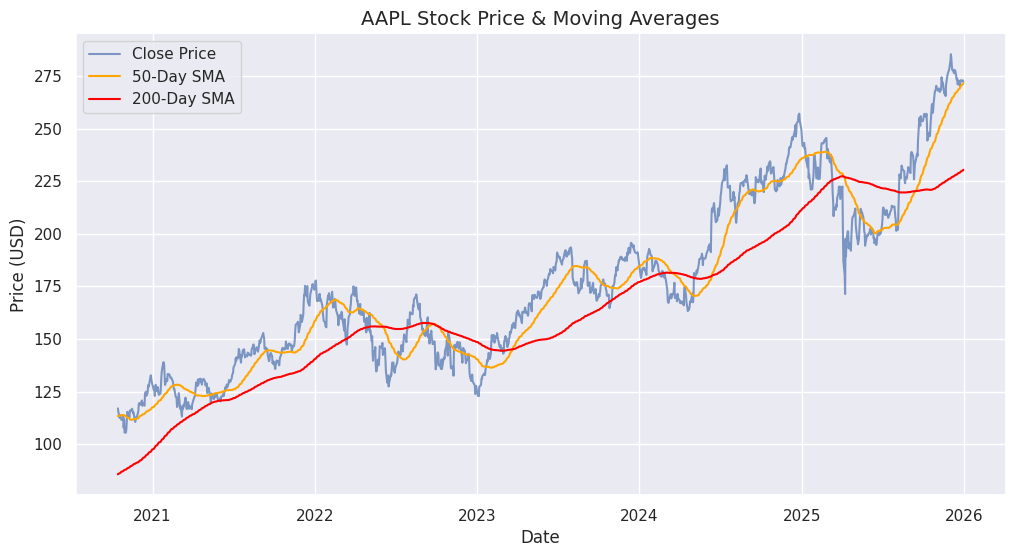

In [13]:
#Visualizing Price Trends & Moving Averages
# Line chart for Price Trend and Moving Averages
plt.figure(figsize=(12, 6))
plt.plot(stock_data_eda.index, stock_data_eda['Close'], label='Close Price', alpha=0.7)
plt.plot(stock_data_eda.index, stock_data_eda['SMA_50'], label='50-Day SMA', color='orange')
plt.plot(stock_data_eda.index, stock_data_eda['SMA_200'], label='200-Day SMA', color='red')

plt.title(f'{ticker_symbol} Stock Price & Moving Averages', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

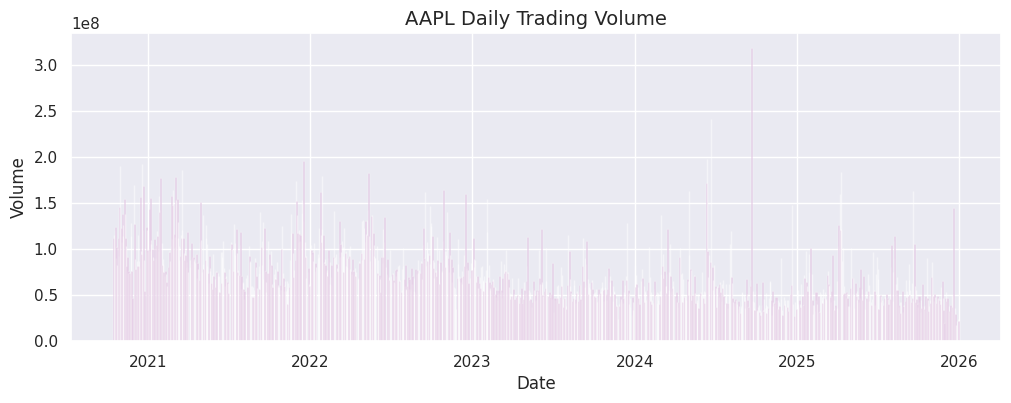

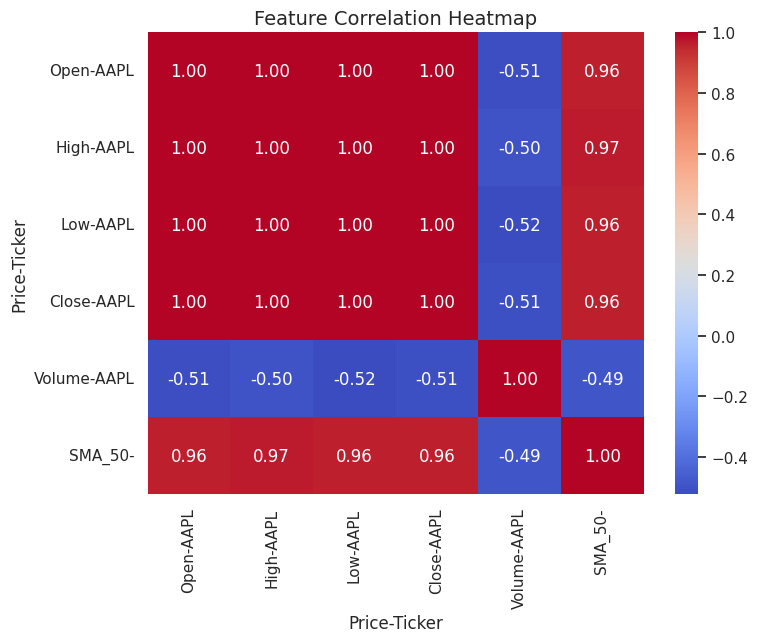

In [15]:
#Trading Volume & Correlation Heatmap

# Subplot for Volume Analysis (Fixed with .values to prevent dimension conflicts)
plt.figure(figsize=(12, 4))
plt.bar(stock_data_eda.index, stock_data_eda['Volume'].values.flatten(), color='purple', alpha=0.5)
plt.title(f'{ticker_symbol} Daily Trading Volume', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Volume')
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(stock_data_eda[['Open', 'High', 'Low', 'Close', 'Volume', 'SMA_50']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Feature Correlation Heatmap', fontsize=14)
plt.show()

In [16]:
#Step 3: Stock Price Prediction Model & Model Training
#Prepare Features and Split Data (Time-Series Split)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Define features (X) and target (y)
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'SMA_50', 'SMA_200']
X = stock_data_eda[features]
y = stock_data_eda['Target']

# Time-series split: Do NOT shuffle financial data! Keep chronological order (e.g., 80% train, 20% test)
train_size = int(len(X) * 0.8)

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1046, 7)
Testing set shape: (262, 7)


In [17]:
#Train the Model & Make Predictions
# Initialize and train the Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

print("Model trained and predictions generated successfully!")

Model trained and predictions generated successfully!


In [18]:
#Step 4: Performance Evaluation & Visualization Dashboard
#Calculate Performance Metrics
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=" * 40)
print("STOCK PRICE PREDICTION - PERFORMANCE METRICS")
print("=" * 40)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")
print("=" * 40)

STOCK PRICE PREDICTION - PERFORMANCE METRICS
Mean Absolute Error (MAE): 9.3039
Mean Squared Error (MSE): 179.4995
Root Mean Squared Error (RMSE): 13.3977
R2 Score: 0.7391


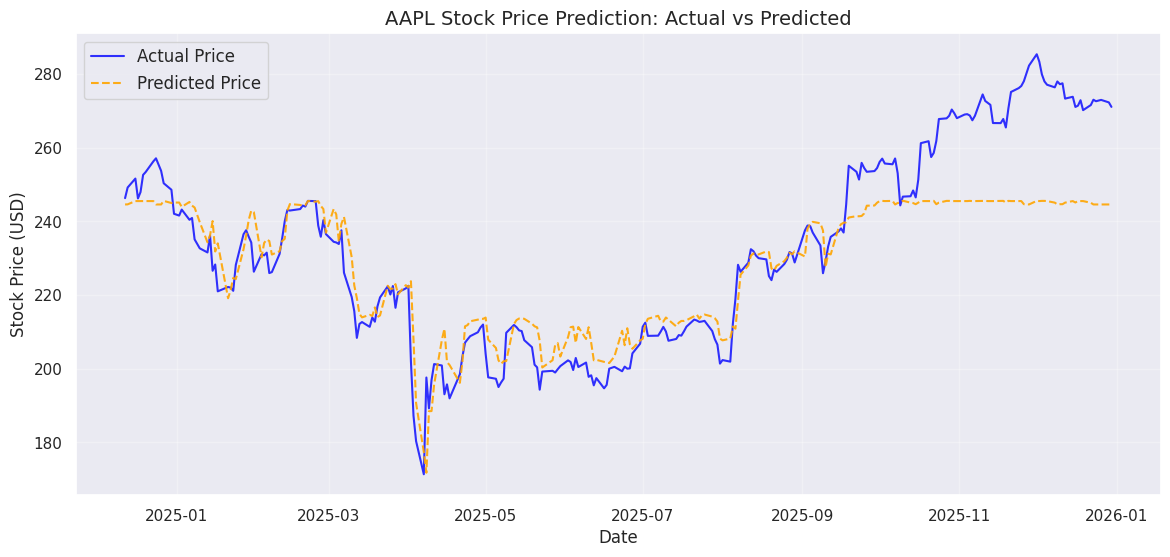

In [19]:
#Actual vs. Predicted Dashboard Visualization
# Create visualization comparing Actual vs Predicted stock prices
plt.figure(figsize=(14, 6))

plt.plot(y_test.index, y_test.values, label='Actual Price', color='blue', alpha=0.8)
plt.plot(y_test.index, y_pred, label='Predicted Price', color='orange', linestyle='--', alpha=0.9)

plt.title(f'{ticker_symbol} Stock Price Prediction: Actual vs Predicted', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Stock Price (USD)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()